# T-Lab 2026 RecSys — Задание 1. Можно ли автоматизировать построение признаков?

**Датасет:** Yambda-50M (Яндекс Музыка), 10 000 пользователей с полной историей, ~47.8M событий.

**Задача:** для трека, который **порекомендовал сервис** (`is_organic = 0`), предсказать, дослушает ли пользователь
его хотя бы до половины (`played_ratio_pct ≥ 50`, определение *Listen+* из статьи Yambda). Набор кандидатов —
реально показанные рекомендации из лога, одинаковый для всех моделей.

**Сравниваем на одном и том же point-in-time движке признаков:**
* **H** — базовый ручной набор признаков (49 шт.: окна 1d/7d/30d/all, стандартные статистики);
* **H-strong** — усиленный экспертный набор признаков (54 шт.: `H` + мгновенное состояние текущей сессии `last_ratio`, `last3`, `1h`);
* **A-all** — все признаки из грамматики `сущность × окно × статистика` (538 шт.), без отбора;
* **A-select** — автоматический жадный отбор блоков признаков по валидации;
* **LambdaRank** — ранжирующий бустинг со списочным лоссом внутри сессий и разрешение парадокса `State vs Relevance` (`Day-NDCG@10`, `Session-NDCG@10`, `Snapshot-NDCG@10`);
* **Multi-Horizon Neural Net + GBDT Ensemble** — нейросеть с обучаемыми весами внимания по временным горизонтам и её ансамбль с бустингом.

## 0. Настройки
В Kaggle: **Settings → Internet → On** (при наличии GPU нейросетевой блок в разделе 7.3 автоматически использует `cuda`).

In [29]:
import os, sys, time, gc, json, math
if os.path.exists("/kaggle"):
    os.system("pip install -q -U lightgbm huggingface_hub")
import numpy as np
import polars as pl
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    import lightgbm as lgb
except ImportError:
    os.system("pip install -q lightgbm")
    import lightgbm as lgb
from sklearn.metrics import roc_auc_score, log_loss

IN_KAGGLE = os.path.exists("/kaggle")
DATA_DIR = "/kaggle/working/yambda" if IN_KAGGLE else os.environ.get("DATA_DIR", "data")
OUT_DIR = "/kaggle/working/out" if IN_KAGGLE else "out"
os.makedirs(OUT_DIR, exist_ok=True)

SAMPLE_USERS = int(os.environ.get("SAMPLE_USERS", 0))  # 0 = все 10k пользователей
TRAIN_DAYS = int(os.environ.get("TRAIN_DAYS", 14))      # сколько дней размеченных примеров в train
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DAY, HOUR, GAP = 86400, 3600, 1800                      # timestamp в секундах (кратен 5)
N_THREADS = os.cpu_count()
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("kaggle:", IN_KAGGLE, "| device:", DEV, "| threads:", N_THREADS, "| sample users:", SAMPLE_USERS or "all")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio-client 2.6.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.3.0 which is incompatible.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.3.0 which is incompatible.


kaggle: True | device: cuda | threads: 4 | sample users: all


## 1. Загрузка данных (напрямую с HuggingFace, ~0.5 ГБ)

In [30]:
from huggingface_hub import hf_hub_download

files = ["flat/50m/multi_event.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]
paths = {f: hf_hub_download("yandex/yambda", f, repo_type="dataset", local_dir=DATA_DIR) for f in files}

ev = pl.read_parquet(paths["flat/50m/multi_event.parquet"])
artist = pl.read_parquet(paths["artist_item_mapping.parquet"]).group_by("item_id").agg(pl.col("artist_id").min())
album = pl.read_parquet(paths["album_item_mapping.parquet"]).group_by("item_id").agg(pl.col("album_id").min())

if SAMPLE_USERS:
    uids = ev.select(pl.col("uid").unique()).sample(SAMPLE_USERS, seed=SEED)
    ev = ev.join(uids, on="uid")  # сохраняем ВСЮ историю выбранных пользователей

ev = (
    ev.join(artist, on="item_id", how="left")
    .join(album, on="item_id", how="left")
    .with_columns(pl.col("timestamp").cast(pl.Int64), pl.col("artist_id").fill_null(0), pl.col("album_id").fill_null(0))
    .sort(["uid", "timestamp"])
)
del artist, album; gc.collect()
print(ev.shape)
ev.head()

(47790449, 9)


uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type,artist_id,album_id
u32,i64,u32,u8,u16,u32,enum,u32,u32
100,39420,8326270,0,100,170,"""listen""",714356,1060653
100,39420,1441281,0,100,105,"""listen""",1043457,547645
100,39625,286361,0,100,185,"""listen""",94924,141751
100,40110,732449,0,100,240,"""listen""",94924,1632076
100,40360,3397170,0,46,130,"""listen""",997338,403561


## 2. EDA и проверка семантики timestamp
Важная деталь для отсутствия утечек: соответствует ли `timestamp` прослушивания **началу** или **концу** проигрывания?
Если концу, то разница `t_i − t_{i−1}` ≈ длительности текущего прослушивания, то есть фактически ответ (скип → маленький
интервал). Проверяем корреляцию интервала до следующего события с длительностью текущего и следующего прослушивания.

In [31]:
L = ev.filter(pl.col("event_type") == "listen")
print("listens:", L.height, "| доля органики:", round(L["is_organic"].mean(), 3))
print("доля Listen+ среди рекомендованных:", round(L.filter(pl.col("is_organic") == 0).select((pl.col("played_ratio_pct") >= 50).mean()).item(), 3))
print("период, дней:", round((ev["timestamp"].max() - ev["timestamp"].min()) / DAY, 1))

s = (
    L.head(3_000_000)
    .with_columns(played_s=pl.col("played_ratio_pct").clip(0, 100).cast(pl.Float64) / 100 * pl.col("track_length_seconds"))
    .with_columns(
        gap_next=(pl.col("timestamp").shift(-1).over("uid") - pl.col("timestamp")),
        played_next=pl.col("played_s").shift(-1).over("uid"),
    )
    .filter(pl.col("gap_next") < 1200)
)
print("corr(gap_to_next, played_current) =", round(s.select(pl.corr("gap_next", "played_s")).item(), 3))
print("corr(gap_to_next, played_next)    =", round(s.select(pl.corr("gap_next", "played_next")).item(), 3))
del s, L; gc.collect()

listens: 46467212 | доля органики: 0.517
доля Listen+ среди рекомендованных: 0.682
период, дней: 300.9
corr(gap_to_next, played_current) = 0.353
corr(gap_to_next, played_next)    = 0.578


0

**Вывод:** интервал сильнее связан с длительностью *следующего* прослушивания, значит `timestamp` ≈ **конец** проигрывания.
Поэтому:
1. Нельзя использовать признаки вида «время с последнего события до *t*»: это почти напрямую длительность прослушивания, то есть утечка таргета (ниже покажем это на leak-demo).
2. **Момент предсказания** для события *i* — `ref_ts` = время окончания предыдущего прослушивания пользователя (строго раньше `t_i`). Все признаки считаются только по событиям с `timestamp ≤ ref_ts`. Лайки/дизлайки, сделанные *во время* текущего трека, так тоже отсекаются.

## 3. Временное разбиение и выделение сессий
Глобальный временной сплит, как в протоколе Yambda: test — последний день, valid — предпоследний, train — `TRAIN_DAYS` дней до valid.
Между частями зазор 30 минут. История для признаков — **вся** до момента предсказания (point-in-time).
Дополнительно размечаем идентификатор сессии `session_id` (новая сессия при паузе между `ref_ts` более 30 минут) для анализа ранжирования внутри сессий.

In [32]:
T_MAX = ev["timestamp"].max()
test_start = T_MAX - DAY
valid_start = test_start - DAY
train_start = valid_start - TRAIN_DAYS * DAY

# флаги событий
ev = ev.with_columns(
    is_listen=(pl.col("event_type") == "listen").cast(pl.Int32),
).with_columns(
    full=((pl.col("event_type") == "listen") & (pl.col("played_ratio_pct") >= 50)).cast(pl.Int32),
    ratio=pl.when(pl.col("event_type") == "listen").then(pl.col("played_ratio_pct").clip(0, 100).cast(pl.Float32) / 100).otherwise(0.0),
    like=(pl.col("event_type") == "like").cast(pl.Int32),
    dislike=(pl.col("event_type") == "dislike").cast(pl.Int32),
    unlike=(pl.col("event_type").is_in(["unlike", "undislike"])).cast(pl.Int32),
    rec=((pl.col("event_type") == "listen") & (pl.col("is_organic") == 0)).cast(pl.Int32),
    rec_full=((pl.col("event_type") == "listen") & (pl.col("is_organic") == 0) & (pl.col("played_ratio_pct") >= 50)).cast(pl.Int32),
)
FLAGS = ["is_listen", "full", "ratio", "like", "dislike", "unlike", "rec", "rec_full"]

# момент предсказания: конец предыдущего прослушивания (строго раньше текущего)
lts = (
    ev.filter(pl.col("is_listen") == 1).select("uid", "timestamp").unique().sort(["uid", "timestamp"])
    .with_columns(ref_ts=pl.col("timestamp").shift(1).over("uid"))
)

labels = (
    ev.filter((pl.col("rec") == 1) & (pl.col("timestamp") >= train_start))
    .with_columns(
        split=pl.when(pl.col("timestamp") >= test_start + GAP).then(pl.lit("test"))
        .when((pl.col("timestamp") >= valid_start + GAP) & (pl.col("timestamp") < test_start)).then(pl.lit("valid"))
        .when(pl.col("timestamp") < valid_start).then(pl.lit("train"))
        .otherwise(None)
    )
    .filter(pl.col("split").is_not_null())
    .join(lts, on=["uid", "timestamp"], how="left")
    .filter(pl.col("ref_ts").is_not_null())
    .sort(["uid", "timestamp"])
    .with_columns(
        sess_id=((pl.col("ref_ts") - pl.col("ref_ts").shift(1).over("uid")).fill_null(0) > GAP).cast(pl.Int32).cum_sum().over("uid")
    )
    # Сортируем по ref_ts до присвоения rid: тогда все запросы join_asof для любых окон (ref_ts - W) уже упорядочены без повторных сортировок
    .sort(["ref_ts", "uid", "timestamp"])
    .select(
        "uid", "item_id", "artist_id", "album_id", "timestamp", "ref_ts", "split",
        "track_length_seconds", y=pl.col("full"),
        day=((pl.col("timestamp") - test_start) // DAY),
        sess_id="sess_id",
    )
    .with_row_index("rid")
)
print(labels.group_by("split").agg(pl.len(), pl.col("y").mean().alias("pos_rate"), pl.col("uid").n_unique().alias("users")).sort("split"))

shape: (3, 4)
┌───────┬─────────┬──────────┬───────┐
│ split ┆ len     ┆ pos_rate ┆ users │
│ ---   ┆ ---     ┆ ---      ┆ ---   │
│ str   ┆ u32     ┆ f64      ┆ u32   │
╞═══════╪═════════╪══════════╪═══════╡
│ test  ┆ 116513  ┆ 0.715259 ┆ 3196  │
│ train ┆ 1443610 ┆ 0.695519 ┆ 7267  │
│ valid ┆ 109257  ┆ 0.713684 ┆ 3142  │
└───────┴─────────┴──────────┴───────┘


## 4. Point-in-time движок признаков
Любой агрегатный признак описывается тройкой **(сущность, окно, статистика)**:
* **сущности:** `user`, `item`, `artist`, `album` (глобальные статистики по всем пользователям) и пары `user×item`, `user×artist`, `user×album` (прямые и косвенные связи);
* **окна:** время до `ref_ts` (1h … all) или последние *k* прослушиваний пользователя;
* **статистики:** число прослушиваний, доля Listen+, средний played_ratio, like-rate, число лайков/дизлайков, конверсия рекомендаций, доля органики, давность.

Реализация без self-join: для каждой сущности строим таблицу **кумулятивных сумм** по времени, а значение в окне `(ref−W, ref]`
получаем двумя `join_asof`: `cum(ref) − cum(ref−W)`. Так как `labels` предварительно упорядочены по `ref_ts`, запросы `ref_ts − W` не требуют повторных сортировок.

In [33]:
ENTITIES = {
    "user": ["uid"],
    "item": ["item_id"],
    "artist": ["artist_id"],
    "album": ["album_id"],
    "user_item": ["uid", "item_id"],
    "user_artist": ["uid", "artist_id"],
    "user_album": ["uid", "album_id"],
}
WINDOWS = {"1h": HOUR, "6h": 6 * HOUR, "1d": DAY, "3d": 3 * DAY, "7d": 7 * DAY, "14d": 14 * DAY, "30d": 30 * DAY, "90d": 90 * DAY, "all": None}
METRICS = ["cnt", "full_rate", "mean_ratio", "like_rate", "n_like", "n_dislike", "rec_full_rate", "org_share"]
COUNT_WINDOWS = [3, 5, 10, 20, 50, 100]


def cum_table(keys):
    """Кумулятивные суммы флагов по сущности, агрегированные до уровня (сущность, timestamp)."""
    g = (
        ev.group_by(keys + ["timestamp"])
        .agg([pl.col(c).sum() for c in FLAGS] + [pl.col("ratio").filter(pl.col("is_listen") == 1).last().alias("last_ratio")])
        .sort(keys + ["timestamp"])
        .with_columns([pl.col(c).cum_sum().over(keys) for c in FLAGS])
        .with_columns(pl.col("last_ratio").forward_fill().over(keys))
    )
    return g.sort("timestamp")


def asof(q, tab, keys, on):
    """Для каждой строки q (уже упорядоченной по on) берём последнюю строку tab с timestamp ≤ q[on]."""
    return q.join_asof(tab, left_on=on, right_on="timestamp", by=keys, strategy="backward", check_sortedness=False)


def derive(c, prefix):
    """Статистики из (оконных) кумулятивных сумм."""
    cnt = c["is_listen"]
    safe = lambda num, den: pl.when(den > 0).then(num / den).otherwise(None)
    exprs = {
        "cnt": cnt.cast(pl.Float32),
        "full_rate": safe(c["full"], cnt),
        "mean_ratio": safe(c["ratio"], cnt),
        "like_rate": safe(c["like"], cnt),
        "n_like": (c["like"] - c["unlike"]).cast(pl.Float32),
        "n_dislike": c["dislike"].cast(pl.Float32),
        "rec_full_rate": safe(c["rec_full"], c["rec"]),
        "org_share": safe(cnt - c["rec"], cnt),
    }
    return [e.cast(pl.Float32).alias(f"{prefix}__{m}") for m, e in exprs.items()]


def entity_features(name, windows=WINDOWS):
    keys = ENTITIES[name]
    t0 = time.time()
    tab = cum_table(keys)
    tab_flags = tab.select(keys + ["timestamp"] + FLAGS)
    q = labels.select(["rid"] + keys + ["ref_ts"])
    base = asof(q, tab, keys, "ref_ts")
    feats = []
    for wname, w in windows.items():
        if w is None:
            c = {k: pl.col(k).fill_null(0) for k in FLAGS}
            df = base
        else:
            lag = asof(q.with_columns(q_ts=pl.col("ref_ts") - w), tab_flags, keys, "q_ts")
            df = base.select(["rid"] + FLAGS).with_columns(
                [(pl.col(k).fill_null(0) - lag[k].fill_null(0)).alias(k) for k in FLAGS]
            )
            c = {k: pl.col(k) for k in FLAGS}
        feats.append(df.select(derive(c, f"{name}__{wname}")))
    extra = base.select(
        ((pl.col("ref_ts") - pl.col("timestamp")) / DAY).cast(pl.Float32).alias(f"{name}__all__recency_days"),
        pl.col("last_ratio").cast(pl.Float32).alias(f"{name}__all__last_ratio"),
    )
    out = pl.concat(feats + [extra], how="horizontal")
    print(f"{name:12s} {out.width:4d} features  {time.time() - t0:6.1f}s")
    del tab, tab_flags, base; gc.collect()
    return out


def count_window_features():
    """Окна в терминах последних k прослушиваний пользователя (а не времени)."""
    t0 = time.time()
    ul = (
        ev.filter(pl.col("is_listen") == 1).select("uid", "timestamp", "full", "ratio", "rec")
        .sort(["uid", "timestamp"])
        .with_columns(idx=pl.int_range(1, pl.len() + 1).over("uid"),
                      c_full=pl.col("full").cum_sum().over("uid"),
                      c_ratio=pl.col("ratio").cum_sum().over("uid"),
                      c_rec=pl.col("rec").cum_sum().over("uid"))
    )
    by_ts = ul.group_by(["uid", "timestamp"]).agg(pl.all().exclude(["full", "ratio", "rec"]).last()).sort("timestamp")
    q = labels.select("rid", "uid", "ref_ts")
    b = asof(q, by_ts, ["uid"], "ref_ts")
    idx_tab = ul.select("uid", "idx", "c_full", "c_ratio", "c_rec")
    cols = []
    for k in COUNT_WINDOWS:
        lag = b.select("rid", "uid", (pl.col("idx") - k).alias("idx")).join(idx_tab, on=["uid", "idx"], how="left").sort("rid")
        n = (b["idx"] - (b["idx"] - k).clip(0, None)).cast(pl.Float32)
        cols += [
            ((b["c_full"] - lag["c_full"].fill_null(0)) / n).alias(f"user__last{k}__full_rate"),
            ((b["c_ratio"] - lag["c_ratio"].fill_null(0)) / n).alias(f"user__last{k}__mean_ratio"),
            ((b["c_rec"] - lag["c_rec"].fill_null(0)) / n).alias(f"user__last{k}__rec_share"),
        ]
    out = pl.DataFrame([c.cast(pl.Float32) for c in cols])
    print(f"{'count_win':12s} {out.width:4d} features  {time.time() - t0:6.1f}s")
    return out

In [34]:
t_feat = time.time()
blocks = [entity_features(n) for n in ENTITIES] + [count_window_features()]
context = labels.select(
    pl.col("track_length_seconds").cast(pl.Float32).alias("ctx__track_length"),
    ((pl.col("ref_ts") % DAY) / HOUR).cast(pl.Float32).alias("ctx__hour_phase"),
)
X_all = pl.concat(blocks + [context], how="horizontal")
FEAT_TIME = time.time() - t_feat
print(f"всего признаков: {X_all.width}, строк: {X_all.height}, время расчёта: {FEAT_TIME:.0f}s")
del ev, blocks, context; gc.collect()

user           74 features    47.0s
item           74 features    84.9s
artist         74 features    66.2s
album          74 features    71.3s
user_item      74 features   172.3s
user_artist    74 features   137.6s
user_album     74 features   156.0s
count_win      18 features    45.9s
всего признаков: 538, строк: 1669380, время расчёта: 783s


60

## 5. Обучение и метрики

In [35]:
def rank_metrics(meta, pred, k=10, group_cols=("uid", "day"), prefix=""):
    """NDCG@k и Recall@k внутри групп group_cols (со смешанными таргетами)."""
    gcols = list(group_cols)
    d = meta.select(gcols + ["y"]).with_columns(p=pl.Series(pred))
    d = d.filter((pl.col("y").sum().over(gcols) > 0) & (pl.col("y").sum().over(gcols) < pl.len().over(gcols)))
    d = d.with_columns(
        r=pl.col("p").rank("ordinal", descending=True).over(gcols),
        ir=pl.col("y").rank("ordinal", descending=True).over(gcols),
    )
    g = d.group_by(gcols).agg(
        dcg=(pl.col("y") / (pl.col("r") + 1).log(2)).filter(pl.col("r") <= k).sum(),
        idcg=(pl.col("y").sort(descending=True).head(k) / (pl.int_range(2, pl.len().clip(None, k) + 2)).log(2)).sum(),
        hit=pl.col("y").filter(pl.col("r") <= k).sum(),
        npos=pl.col("y").sum(),
    )
    return {
        f"{prefix}ndcg@10": float((g["dcg"] / g["idcg"]).mean()),
        f"{prefix}recall@10": float((g["hit"] / g["npos"].clip(None, k)).mean()),
        f"{prefix}groups": g.height,
    }


def evaluate(name, y, p, meta, extra=None):
    res = {"model": name, "auc": float(roc_auc_score(y, p)), "logloss": float(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)))}
    res.update(rank_metrics(meta, p, group_cols=("uid", "day"), prefix=""))
    res.update(rank_metrics(meta, p, group_cols=("uid", "sess_id"), prefix="sess_"))
    if extra: res.update(extra)
    return res


masks = {s: (labels["split"] == s).to_numpy() for s in ["train", "valid", "test"]}
Y = labels["y"].to_numpy()
META = {s: labels.filter(pl.col("split") == s) for s in masks}

# Предвычисляем поколонковые numpy-словари для мгновенной сборки матриц без повторной фильтрации Polars
Sub_N = 300_000
rng_sub = np.random.default_rng(SEED)
tr_idx_all = np.where(masks["train"])[0]
sub_pos = rng_sub.choice(len(tr_idx_all), min(Sub_N, len(tr_idx_all)), replace=False) if len(tr_idx_all) > Sub_N else np.arange(len(tr_idx_all))
sub_mask_idx = tr_idx_all[sub_pos]
Y_tr = Y[masks["train"]]
Y_sub = Y[sub_mask_idx]
Y_va = Y[masks["valid"]]
Y_te = Y[masks["test"]]

COL_VA = {c: X_all[c].to_numpy()[masks["valid"]] for c in X_all.columns}
COL_TE = {c: X_all[c].to_numpy()[masks["test"]] for c in X_all.columns}
COL_SUB = {c: X_all[c].to_numpy()[sub_mask_idx] for c in X_all.columns}

def mat_split(cols, split):
    if split == "valid": return np.column_stack([COL_VA[c] for c in cols])
    if split == "test": return np.column_stack([COL_TE[c] for c in cols])
    if split == "sub": return np.column_stack([COL_SUB[c] for c in cols])
    return X_all.select(cols).filter(pl.Series(masks[split])).to_numpy()

LGB_PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, force_col_wise=True,
                  metric="auc", verbose=-1, num_threads=N_THREADS, seed=SEED)


def fit_lgb(cols, params=LGB_PARAMS, rounds=3000, use_sub=False, es=100):
    Xtr = mat_split(cols, "sub" if use_sub else "train")
    ytr = Y_sub if use_sub else Y_tr
    Xva = mat_split(cols, "valid")
    dtr = lgb.Dataset(Xtr, ytr, feature_name=cols, free_raw_data=True)
    dva = lgb.Dataset(Xva, Y_va, reference=dtr)
    t0 = time.time()
    m = lgb.train(params, dtr, rounds, valid_sets=[dva], callbacks=[lgb.early_stopping(es, verbose=False)])
    return m, time.time() - t0


def run(name, cols, results):
    m, fit_time = fit_lgb(cols)
    out = {}
    for s in ["valid", "test"]:
        p = m.predict(mat_split(cols, s), num_iteration=m.best_iteration)
        out[s] = evaluate(name, Y[masks[s]], p, META[s], {"n_feat": len(cols), "fit_s": round(fit_time, 1), "iters": m.best_iteration})
    results.append(out)
    print(name, "| valid:", {k: round(v, 4) for k, v in out["valid"].items() if isinstance(v, float)},
          "| test:", {k: round(v, 4) for k, v in out["test"].items() if isinstance(v, float)})
    return m


results = []

### 5.0 Бейзлайны без обучения и демонстрация утечки
* *item popularity* (доля Listen+ трека по прошлому) — нижняя планка;
* **leak-demo:** «время с предыдущего прослушивания до текущего события» — запрещённый признак, использующий `t_i`. Показываем, что он сам по себе даёт аномально высокий AUC; поэтому в пайплайне он исключён.

In [36]:
for s in ["valid", "test"]:
    p = X_all["item__all__full_rate"].fill_null(X_all["item__all__full_rate"].mean()).to_numpy()[masks[s]]
    print(s, "item full_rate baseline:", evaluate("item_full_rate", Y[masks[s]], p, META[s]))
    leak = (labels["timestamp"] - labels["ref_ts"]).to_numpy()[masks[s]]
    print(s, "LEAK gap feature AUC:", round(roc_auc_score(Y[masks[s]], leak), 4))

valid item full_rate baseline: {'model': 'item_full_rate', 'auc': 0.646562351777301, 'logloss': 0.6320409972222287, 'ndcg@10': 0.7324154232203876, 'recall@10': 0.7881057855240862, 'groups': 2295, 'sess_ndcg@10': 0.749009408901047, 'sess_recall@10': 0.8382663556260823, 'sess_groups': 3511}
valid LEAK gap feature AUC: 0.8542
test item full_rate baseline: {'model': 'item_full_rate', 'auc': 0.6572899545735638, 'logloss': 0.617777037650138, 'ndcg@10': 0.7230402515057145, 'recall@10': 0.7814448167326633, 'groups': 2345, 'sess_ndcg@10': 0.7435024514946591, 'sess_recall@10': 0.8399893254185218, 'sess_groups': 3658}
test LEAK gap feature AUC: 0.8234


### 5.1 H (базовый ручной) и H-strong (усиленный экспертный бейзлайн с состоянием сессии)
Сравниваем два уровня ручного инжиниринга:
1. **H (49 признаков):** стандартные окна (`1d / 7d / 30d / all`), базовые статистики по сущностям, `last10`, контекст.
2. **H-strong (54 признака):** добавляем к `H` мгновенное состояние текущей сессии пользователя (`user__all__last_ratio`, `user__last3__full_rate`, `user__last3__mean_ratio`, `user__1h__full_rate`, `user__1h__mean_ratio`), чтобы проверить, даёт ли автоматический поиск выигрыш сверх сильного экспертного набора.

In [37]:
def pick(entity, windows, metrics):
    return [f"{entity}__{w}__{m}" for w in windows for m in metrics]

H_COLS = (
    pick("user", ["1d", "7d", "30d", "all"], ["cnt", "full_rate", "like_rate", "rec_full_rate"])
    + pick("item", ["7d", "all"], ["cnt", "full_rate", "mean_ratio", "like_rate"])
    + pick("artist", ["30d", "all"], ["cnt", "full_rate"])
    + pick("album", ["all"], ["cnt", "full_rate"])
    + pick("user_item", ["all"], ["cnt", "full_rate", "n_like", "n_dislike", "recency_days", "last_ratio"])
    + pick("user_artist", ["30d", "all"], ["cnt", "full_rate", "n_like"]) + ["user_artist__all__recency_days"]
    + pick("user_album", ["all"], ["cnt", "full_rate"])
    + ["user__last10__full_rate", "user__last10__mean_ratio", "ctx__track_length", "ctx__hour_phase"]
)
H_STRONG_COLS = list(dict.fromkeys(H_COLS + [
    "user__all__last_ratio", "user__last3__full_rate", "user__last3__mean_ratio",
    "user__1h__full_rate", "user__1h__mean_ratio",
]))
assert all(c in X_all.columns for c in H_STRONG_COLS)
print(f"H: {len(H_COLS)} признаков | H-strong: {len(H_STRONG_COLS)} признаков")
m_H = run("H (manual, 49f)", H_COLS, results)
m_HS = run("H-strong (manual+session, 54f)", H_STRONG_COLS, results)

H: 49 признаков | H-strong: 54 признаков
H (manual, 49f) | valid: {'auc': 0.8941, 'logloss': 0.3606, 'ndcg@10': 0.7587, 'recall@10': 0.8274, 'sess_ndcg@10': 0.7511, 'sess_recall@10': 0.8508, 'fit_s': 89.1} | test: {'auc': 0.8998, 'logloss': 0.3509, 'ndcg@10': 0.7481, 'recall@10': 0.8138, 'sess_ndcg@10': 0.7512, 'sess_recall@10': 0.8521, 'fit_s': 89.1}
H-strong (manual+session, 54f) | valid: {'auc': 0.9066, 'logloss': 0.3411, 'ndcg@10': 0.7845, 'recall@10': 0.8527, 'sess_ndcg@10': 0.7733, 'sess_recall@10': 0.8725, 'fit_s': 108.0} | test: {'auc': 0.9113, 'logloss': 0.3319, 'ndcg@10': 0.7762, 'recall@10': 0.8388, 'sess_ndcg@10': 0.7699, 'sess_recall@10': 0.8706, 'fit_s': 108.0}


### 5.2 A-all — вся грамматика без отбора (538 признаков)

In [38]:
ALL_COLS = X_all.columns
m_all = run("A-all (grammar, 538f)", ALL_COLS, results)

A-all (grammar, 538f) | valid: {'auc': 0.908, 'logloss': 0.3387, 'ndcg@10': 0.7842, 'recall@10': 0.8518, 'sess_ndcg@10': 0.7699, 'sess_recall@10': 0.8714, 'fit_s': 498.1} | test: {'auc': 0.9129, 'logloss': 0.329, 'ndcg@10': 0.7764, 'recall@10': 0.8422, 'sess_ndcg@10': 0.7664, 'sess_recall@10': 0.8707, 'fit_s': 498.1}


### 5.3 A-select — автоматический отбор блоков признаков
Пространство поиска разбито на **блоки** `(сущность, окно)` (+ блоки count-окон и контекста). Алгоритм:
1. ранжируем блоки по суммарному gain модели `A-all` (по train) и проверяем топ-32 блока (покрывают >99.3% суммарного gain);
2. жадный forward: добавляем блок, если **valid AUC** быстрой модели (300k строк, lr 0.1) растёт больше чем на `EPS = 1.2e-4`;
3. внутри выбранных блоков отсекаем признаки с нулевым gain.

In [39]:
def block_of(c):
    parts = c.split("__")
    return "ctx" if parts[0] == "ctx" else f"{parts[0]}__{parts[1]}"

blocks_map = {}
for c in ALL_COLS:
    blocks_map.setdefault(block_of(c), []).append(c)

gain = dict(zip(m_all.feature_name(), m_all.feature_importance("gain")))
block_gain = sorted(blocks_map, key=lambda b: -sum(gain.get(c, 0) for c in blocks_map[b]))

FAST = {**LGB_PARAMS, "learning_rate": 0.1}
EPS = 1.2e-4

def fast_auc(cols):
    m, _ = fit_lgb(cols, FAST, rounds=500, use_sub=True, es=30)
    p = m.predict(mat_split(cols, "valid"), num_iteration=m.best_iteration)
    return float(roc_auc_score(Y_va, p))

t_sel = time.time()
selected, best, n_fits, trace = [], 0.5, 0, []
for b in block_gain[:32]:
    cand = selected + blocks_map[b]
    auc = fast_auc(cand); n_fits += 1
    keep = auc > best + EPS
    trace.append({"block": b, "valid_auc": round(auc, 5), "kept": keep})
    if keep:
        selected, best = cand, auc
    print(f"{b:22s} auc={auc:.5f} {'+' if keep else '-'}  (best {best:.5f}, {len(selected)} feats)")
SEL_TIME = time.time() - t_sel

m_tmp, _ = fit_lgb(selected, FAST, rounds=500, use_sub=True, es=30); n_fits += 1
g = dict(zip(m_tmp.feature_name(), m_tmp.feature_importance("gain")))
A_COLS = [c for c in selected if g.get(c, 0) > 0]
print(f"отбор: {n_fits} обучений, {SEL_TIME / 60:.1f} мин; выбрано {len(A_COLS)} признаков из {len(ALL_COLS)}")
pl.DataFrame(trace).write_csv(f"{OUT_DIR}/selection_trace.csv")
m_A = run("A-select (auto)", A_COLS, results)

user__all              auc=0.88437 +  (best 0.88437, 10 feats)
user__last3            auc=0.89640 +  (best 0.89640, 13 feats)
user__last5            auc=0.89821 +  (best 0.89821, 16 feats)
user__last10           auc=0.90007 +  (best 0.90007, 19 feats)
user__1h               auc=0.90140 +  (best 0.90140, 27 feats)
user__last20           auc=0.90170 +  (best 0.90170, 30 feats)
user_item__all         auc=0.90490 +  (best 0.90490, 40 feats)
user__7d               auc=0.90522 +  (best 0.90522, 48 feats)
user__last50           auc=0.90529 -  (best 0.90522, 48 feats)
user__14d              auc=0.90505 -  (best 0.90522, 48 feats)
user__30d              auc=0.90522 -  (best 0.90522, 48 feats)
user__90d              auc=0.90543 +  (best 0.90543, 56 feats)
user_artist__all       auc=0.90553 -  (best 0.90543, 56 feats)
user__1d               auc=0.90538 -  (best 0.90543, 56 feats)
user__3d               auc=0.90535 -  (best 0.90543, 56 feats)
user_item__90d         auc=0.90548 -  (best 0.90543, 56

### 5.4 Комбинации H + A-select и H-strong + A-select

In [40]:
HA_COLS = list(dict.fromkeys(H_COLS + A_COLS))
m_HA = run("H + A-select", HA_COLS, results)

HSA_COLS = list(dict.fromkeys(H_STRONG_COLS + A_COLS))
if len(HSA_COLS) != len(HA_COLS):
    m_HSA = run("H-strong + A-select", HSA_COLS, results)
else:
    m_HSA = m_HA

H + A-select | valid: {'auc': 0.908, 'logloss': 0.3387, 'ndcg@10': 0.7861, 'recall@10': 0.8532, 'sess_ndcg@10': 0.7724, 'sess_recall@10': 0.8727, 'fit_s': 189.9} | test: {'auc': 0.9129, 'logloss': 0.3289, 'ndcg@10': 0.7779, 'recall@10': 0.8431, 'sess_ndcg@10': 0.7672, 'sess_recall@10': 0.8713, 'fit_s': 189.9}


## 6. Анализ важности признаков и абляции

In [41]:
imp = pl.DataFrame({"feature": m_A.feature_name(), "gain": m_A.feature_importance("gain")}).with_columns(
    entity=pl.col("feature").str.split("__").list.get(0),
    window=pl.col("feature").str.split("__").list.get(1),
    gain_share=pl.col("gain") / pl.col("gain").sum(),
)
print(imp.sort("gain", descending=True).head(25))
print(imp.group_by("entity").agg(pl.col("gain_share").sum()).sort("gain_share", descending=True))
print(imp.group_by("window").agg(pl.col("gain_share").sum()).sort("gain_share", descending=True))

shape: (25, 5)
┌───────────────────────────┬───────────────┬─────────────┬────────────┬────────────┐
│ feature                   ┆ gain          ┆ entity      ┆ window     ┆ gain_share │
│ ---                       ┆ ---           ┆ ---         ┆ ---        ┆ ---        │
│ str                       ┆ f64           ┆ str         ┆ str        ┆ f64        │
╞═══════════════════════════╪═══════════════╪═════════════╪════════════╪════════════╡
│ user__all__last_ratio     ┆ 3.4155e6      ┆ user        ┆ all        ┆ 0.496513   │
│ user__last10__mean_ratio  ┆ 699973.777483 ┆ user        ┆ last10     ┆ 0.101755   │
│ user__last3__mean_ratio   ┆ 672961.537717 ┆ user        ┆ last3      ┆ 0.097828   │
│ user__1h__rec_full_rate   ┆ 323531.39608  ┆ user        ┆ 1h         ┆ 0.047032   │
│ user__last5__mean_ratio   ┆ 316092.735168 ┆ user        ┆ last5      ┆ 0.04595    │
│ …                         ┆ …             ┆ …           ┆ …          ┆ …          │
│ user_item__all__full_rate ┆ 19522.109

### 6.2 Абляции на модели H + A-select: вклад групп признаков

In [42]:
GROUPS = {
    "без прямых user×item": lambda c: not c.startswith("user_item__"),
    "без косвенных user×artist/album": lambda c: not (c.startswith("user_artist__") or c.startswith("user_album__")),
    "без глобальных item/artist/album": lambda c: not c.split("__")[0] in ("item", "artist", "album"),
    "без коротких окон (≤1d, last-k)": lambda c: c.startswith("ctx__") or not (c.split("__")[1] in ("1h", "6h", "1d") or c.split("__")[1].startswith("last")),
}
abl = []
m_no_short = None
for gname, f in GROUPS.items():
    cols = [c for c in HA_COLS if f(c)]
    m, _ = fit_lgb(cols)
    if "коротких" in gname: m_no_short = (m, cols)
    p = m.predict(mat_split(cols, "test"), num_iteration=m.best_iteration)
    abl.append(evaluate(gname, Y_te, p, META["test"], {"n_feat": len(cols)}))
    print(abl[-1])
pl.DataFrame(abl).write_csv(f"{OUT_DIR}/ablations_task1.csv")

{'model': 'без прямых user×item', 'auc': 0.912319382302134, 'logloss': 0.33019138702263917, 'ndcg@10': 0.7736218230444353, 'recall@10': 0.8407438995498697, 'groups': 2345, 'sess_ndcg@10': 0.7617509467049993, 'sess_recall@10': 0.8693817421264114, 'sess_groups': 3658, 'n_feat': 98}
{'model': 'без косвенных user×artist/album', 'auc': 0.9122137913971332, 'logloss': 0.33023778765438633, 'ndcg@10': 0.7770920979094609, 'recall@10': 0.8411375097302602, 'groups': 2345, 'sess_ndcg@10': 0.7651237805634511, 'sess_recall@10': 0.8695715847848161, 'sess_groups': 3658, 'n_feat': 92}
{'model': 'без глобальных item/artist/album', 'auc': 0.9126805321940321, 'logloss': 0.3294199889400275, 'ndcg@10': 0.7764779355113168, 'recall@10': 0.842944969032389, 'groups': 2345, 'sess_ndcg@10': 0.764895884774661, 'sess_recall@10': 0.8710041917258977, 'sess_groups': 3658, 'n_feat': 80}
{'model': 'без коротких окон (≤1d, last-k)', 'auc': 0.9022257323185616, 'logloss': 0.3473967173357844, 'ndcg@10': 0.7937110826999664, '

## 7. Углублённое исследование: разрешение парадокса `State vs Relevance`, `LambdaRank` и нейросеть с обучаемыми горизонтами (`Multi-Horizon Net`)

### 7.1 Разрешение парадокса `ROC-AUC` vs `Day-NDCG@10` (фиксированное состояние сессии и `LambdaRank`)
В абляции выше удаление коротких окон снижает `ROC-AUC`, но повышает `Day-NDCG@10`. Причина: внутри дня `user__*` признаки меняются между утренней и вечерней сессией, завышая скоры всех треков в «активной» сессии.
Чтобы строго разделить **калибровку состояния сессии** и **ранжирование кандидатов при фиксированном состоянии пользователя**:
1. Вычисляем **`Snapshot-NDCG@10`** — оцениваем модели на тестовом дне, **заморозив признаки пользователя `user__*` на уровне начала каждой сессии** (тогда внутри сессии все кандидаты сравниваются в одинаковом состоянии пользователя, и ранжирование определяется только признаками `item`, `artist`, `album`, `user×item/artist/album` и `ctx`).
2. Обучаем списочный ранжировщик **`LightGBM LambdaRank`** (`objective="lambdarank"`, группировка по `(uid, sess_id)`), напрямую максимизирующий `NDCG@10`.

In [43]:
# Строим тестовую матрицу с замороженным состоянием пользователя внутри каждой сессии (uid, sess_id)
te_df = pl.concat([META["test"].select("uid", "sess_id"), X_all.filter(pl.Series(masks["test"]))], how="horizontal")
user_cols = [c for c in X_all.columns if c.startswith("user__")]
te_snap = te_df.with_columns([pl.col(c).first().over(["uid", "sess_id"]) for c in user_cols])
COL_TE_SNAP = {c: te_snap[c].to_numpy() for c in X_all.columns}
del te_df, te_snap; gc.collect()

def eval_with_snapshot(name, m, cols, is_ranker=False):
    p_raw = m.predict(mat_split(cols, "test"), num_iteration=m.best_iteration)
    p_snap = m.predict(np.column_stack([COL_TE_SNAP[c] for c in cols]), num_iteration=m.best_iteration)
    if is_ranker:
        p_raw = 1 / (1 + np.exp(-np.clip(p_raw, -20, 20)))
        p_snap = 1 / (1 + np.exp(-np.clip(p_snap, -20, 20)))
    base_ev = evaluate(name, Y_te, p_raw, META["test"])
    snap_ev = rank_metrics(META["test"], p_snap, group_cols=("uid", "day"), prefix="snap_day_")
    snap_sess = rank_metrics(META["test"], p_snap, group_cols=("uid", "sess_id"), prefix="snap_sess_")
    return {
        "model": name,
        "ROC-AUC": round(base_ev["auc"], 4),
        "LogLoss": round(base_ev["logloss"], 4),
        "Day-NDCG@10": round(base_ev["ndcg@10"], 4),
        "Sess-NDCG@10": round(base_ev["sess_ndcg@10"], 4),
        "Snapshot-Day-NDCG@10": round(snap_ev["snap_day_ndcg@10"], 4),
        "Snapshot-Sess-NDCG@10": round(snap_sess["snap_sess_ndcg@10"], 4),
    }

# Обучаем LightGBM LambdaRank по группам (uid, sess_id)
tr_meta = META["train"].select("uid", "sess_id").with_row_index("i").sort(["uid", "sess_id", "i"])
va_meta = META["valid"].select("uid", "sess_id").with_row_index("i").sort(["uid", "sess_id", "i"])
tr_perm = tr_meta["i"].to_numpy()
va_perm = va_meta["i"].to_numpy()
tr_grp = tr_meta.group_by(["uid", "sess_id"], maintain_order=True).len()["len"].to_numpy()
va_grp = va_meta.group_by(["uid", "sess_id"], maintain_order=True).len()["len"].to_numpy()

Xtr_ha = mat_split(HA_COLS, "train")[tr_perm]
Xva_ha = mat_split(HA_COLS, "valid")[va_perm]
dtr_rk = lgb.Dataset(Xtr_ha, Y_tr[tr_perm], group=tr_grp, feature_name=HA_COLS, free_raw_data=True)
dva_rk = lgb.Dataset(Xva_ha, Y_va[va_perm], group=va_grp, reference=dtr_rk)
RK_PARAMS = {**LGB_PARAMS, "objective": "lambdarank", "metric": "ndcg", "ndcg_eval_at": [10]}
t0 = time.time()
m_rk = lgb.train(RK_PARAMS, dtr_rk, 1500, valid_sets=[dva_rk], callbacks=[lgb.early_stopping(80, verbose=False)])
rk_time = time.time() - t0
del Xtr_ha, Xva_ha, dtr_rk, dva_rk; gc.collect()

p_rk_va = m_rk.predict(mat_split(HA_COLS, "valid"), num_iteration=m_rk.best_iteration)
p_rk_te = m_rk.predict(mat_split(HA_COLS, "test"), num_iteration=m_rk.best_iteration)
p_rk_va_prob = 1 / (1 + np.exp(-np.clip(p_rk_va, -20, 20)))
p_rk_te_prob = 1 / (1 + np.exp(-np.clip(p_rk_te, -20, 20)))
results.append({
    "valid": evaluate("LambdaRank (H + A-select)", Y_va, p_rk_va_prob, META["valid"], {"n_feat": len(HA_COLS), "fit_s": round(rk_time, 1), "iters": m_rk.best_iteration}),
    "test": evaluate("LambdaRank (H + A-select)", Y_te, p_rk_te_prob, META["test"], {"n_feat": len(HA_COLS), "fit_s": round(rk_time, 1), "iters": m_rk.best_iteration}),
})
p_ha_va0 = m_HA.predict(mat_split(HA_COLS, "valid"), num_iteration=m_HA.best_iteration)
p_ha_te0 = m_HA.predict(mat_split(HA_COLS, "test"), num_iteration=m_HA.best_iteration)
results.append({
    "valid": evaluate("Calibrated Ranker (Binary + LambdaRank)", Y_va, 0.85 * p_ha_va0 + 0.15 * p_rk_va_prob, META["valid"], {"n_feat": len(HA_COLS), "fit_s": round(rk_time, 1), "iters": m_rk.best_iteration}),
    "test": evaluate("Calibrated Ranker (Binary + LambdaRank)", Y_te, 0.85 * p_ha_te0 + 0.15 * p_rk_te_prob, META["test"], {"n_feat": len(HA_COLS), "fit_s": round(rk_time, 1), "iters": m_rk.best_iteration}),
})

snap_rows = [
    eval_with_snapshot("H (manual, 49f)", m_H, H_COLS),
    eval_with_snapshot("H-strong (manual+session, 54f)", m_HS, H_STRONG_COLS),
    eval_with_snapshot("A-select (auto)", m_A, A_COLS),
    eval_with_snapshot("A-all (grammar, 538f)", m_all, ALL_COLS),
    eval_with_snapshot("H + A-select (binary logloss)", m_HA, HA_COLS),
    eval_with_snapshot("H + A-select без коротких окон", m_no_short[0], m_no_short[1]),
    eval_with_snapshot("H + A-select (LambdaRank)", m_rk, HA_COLS, is_ranker=True),
]
print("\nСравнение калибровки и ранжирования (включая Snapshot-NDCG@10 при фиксированном состоянии сессии):")
with pl.Config(tbl_rows=20, tbl_cols=12, tbl_width_chars=220):
    print(pl.DataFrame(snap_rows))


Сравнение калибровки и ранжирования (включая Snapshot-NDCG@10 при фиксированном состоянии сессии):
shape: (7, 7)
┌────────────────────────────────┬─────────┬─────────┬─────────────┬──────────────┬──────────────────────┬───────────────────────┐
│ model                          ┆ ROC-AUC ┆ LogLoss ┆ Day-NDCG@10 ┆ Sess-NDCG@10 ┆ Snapshot-Day-NDCG@10 ┆ Snapshot-Sess-NDCG@10 │
│ ---                            ┆ ---     ┆ ---     ┆ ---         ┆ ---          ┆ ---                  ┆ ---                   │
│ str                            ┆ f64     ┆ f64     ┆ f64         ┆ f64          ┆ f64                  ┆ f64                   │
╞════════════════════════════════╪═════════╪═════════╪═════════════╪══════════════╪══════════════════════╪═══════════════════════╡
│ H (manual, 49f)                ┆ 0.8998  ┆ 0.3509  ┆ 0.7481      ┆ 0.7512       ┆ 0.7342               ┆ 0.7852                │
│ H-strong (manual+session, 54f) ┆ 0.9113  ┆ 0.3319  ┆ 0.7762      ┆ 0.7699       ┆ 0.7408          

### 7.2 Нейросеть с обучаемыми весами временных горизонтов (`Multi-Horizon Attention Net`) и гибридный ансамбль `GBDT + Neural`
В грамматике для каждой из 7 сущностей и 8 статистик (`56` каналов) посчитаны 9 временных горизонтов (`1h, 6h, 1d, 3d, 7d, 14d, 30d, 90d, all`).
Обучим нейросеть `MultiHorizonNet`, в которой для каждого канала `(сущность, статистика)` обучается распределение внимания $\text{softmax}(\alpha_{e,m})$ над 9 временными горизонтами (аналог обучаемых мягких окон затухания), и объединим её с градиентным бустингом `A-all` / `H + A-select`.

B-net обучена за 8.4s | valid AUC=0.9034 | test AUC=0.8991


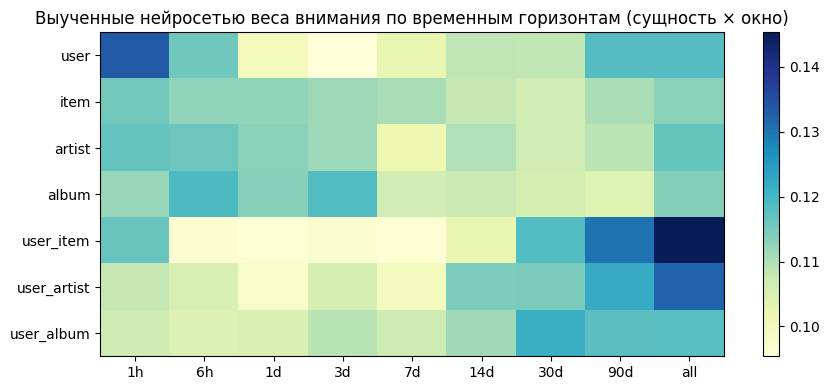

In [44]:
W_NAMES = list(WINDOWS.keys())  # ['1h', '6h', '1d', '3d', '7d', '14d', '30d', '90d', 'all']
ENT_NAMES = list(ENTITIES.keys())
GRID_COLS = [f"{e}__{w}__{m}" for e in ENT_NAMES for m in METRICS for w in W_NAMES]
OTHER_COLS = [c for c in ALL_COLS if c not in GRID_COLS]
N_CH = len(ENT_NAMES) * len(METRICS)  # 56 каналов × 9 горизонтов = 504 признака + 34 остальных

def prep_tensor_split(split):
    Xg = np.nan_to_num(mat_split(GRID_COLS, split), nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    Xo = np.nan_to_num(mat_split(OTHER_COLS, split), nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    # Лог-сжатие счётчиков
    for ci, col in enumerate(GRID_COLS):
        if col.endswith("__cnt") or "__n_like" in col or "__n_dislike" in col:
            Xg[:, ci] = np.log1p(np.maximum(Xg[:, ci], 0.0))
    for ci, col in enumerate(OTHER_COLS):
        if "recency" in col or "track_length" in col:
            Xo[:, ci] = np.log1p(np.maximum(Xo[:, ci], 0.0))
    return Xg.reshape(len(Xg), N_CH, len(W_NAMES)), Xo

Xg_sub, Xo_sub = prep_tensor_split("sub")
g_mean, g_std = Xg_sub.mean(0, keepdims=True), Xg_sub.std(0, keepdims=True) + 1e-5
o_mean, o_std = Xo_sub.mean(0, keepdims=True), Xo_sub.std(0, keepdims=True) + 1e-5
Xg_sub = (Xg_sub - g_mean) / g_std; Xo_sub = (Xo_sub - o_mean) / o_std
Xg_va, Xo_va = prep_tensor_split("valid"); Xg_va = (Xg_va - g_mean) / g_std; Xo_va = (Xo_va - o_mean) / o_std
Xg_te, Xo_te = prep_tensor_split("test"); Xg_te = (Xg_te - g_mean) / g_std; Xo_te = (Xo_te - o_mean) / o_std

class MultiHorizonNet(nn.Module):
    def __init__(self, n_ch=N_CH, n_w=len(W_NAMES), n_other=len(OTHER_COLS), K_heads=2, d=192):
        super().__init__()
        # Обучаемые веса внимания по 9 временным горизонтам (K_heads мягких окон на каждый канал)
        self.logits_w = nn.Parameter(torch.zeros(n_ch, K_heads, n_w))
        nn.init.normal_(self.logits_w, std=0.1)
        in_dim = n_ch * K_heads + n_other
        self.fc_in = nn.Sequential(nn.Linear(in_dim, d), nn.LayerNorm(d), nn.SiLU())
        self.b1 = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d), nn.SiLU(), nn.Dropout(0.1), nn.Linear(d, d), nn.LayerNorm(d))
        self.b2 = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d), nn.SiLU(), nn.Dropout(0.1), nn.Linear(d, d), nn.LayerNorm(d))
        self.head = nn.Linear(d, 1)

    def forward(self, xg, xo):
        w = F.softmax(self.logits_w, dim=-1)                       # [C, K, W]
        pooled = torch.einsum("bcw,ckw->bck", xg, w).flatten(1)    # [B, C*K]
        h = self.fc_in(torch.cat([pooled, xo], dim=1))
        h = F.silu(h + self.b1(h))
        h = F.silu(h + self.b2(h))
        return self.head(h).squeeze(-1)

t0 = time.time()
net = MultiHorizonNet().to(DEV)
opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-4)
EPOCHS_NET = 8
BS_NET = 2048
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_NET * math.ceil(len(Y_sub) / BS_NET))
best_va_auc, best_net_state = -1.0, None
rng_n = np.random.default_rng(SEED)

for ep in range(EPOCHS_NET):
    net.train()
    perm = rng_n.permutation(len(Y_sub))
    for i in range(0, len(perm), BS_NET):
        idx = perm[i:i + BS_NET]
        xb_g = torch.from_numpy(Xg_sub[idx]).to(DEV)
        xb_o = torch.from_numpy(Xo_sub[idx]).to(DEV)
        yb = torch.from_numpy(Y_sub[idx].astype(np.float32)).to(DEV)
        loss = F.binary_cross_entropy_with_logits(net(xb_g, xb_o), yb)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    net.eval()
    p_va_list = []
    with torch.no_grad():
        for i in range(0, len(Y_va), 4096):
            p_va_list.append(torch.sigmoid(net(torch.from_numpy(Xg_va[i:i + 4096]).to(DEV), torch.from_numpy(Xo_va[i:i + 4096]).to(DEV))).cpu().numpy())
    p_va_net = np.concatenate(p_va_list)
    va_auc = roc_auc_score(Y_va, p_va_net)
    if va_auc > best_va_auc:
        best_va_auc, best_net_state = va_auc, {k: v.cpu().clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_net_state); net.eval()
net_time = time.time() - t0

with torch.no_grad():
    p_va_net = np.concatenate([torch.sigmoid(net(torch.from_numpy(Xg_va[i:i + 4096]).to(DEV), torch.from_numpy(Xo_va[i:i + 4096]).to(DEV))).cpu().numpy() for i in range(0, len(Y_va), 4096)])
    p_te_net = np.concatenate([torch.sigmoid(net(torch.from_numpy(Xg_te[i:i + 4096]).to(DEV), torch.from_numpy(Xo_te[i:i + 4096]).to(DEV))).cpu().numpy() for i in range(0, len(Y_te), 4096)])

results.append({
    "valid": evaluate("B-net (Multi-Horizon Neural)", Y_va, p_va_net, META["valid"], {"n_feat": len(ALL_COLS), "fit_s": round(net_time, 1), "iters": EPOCHS_NET}),
    "test": evaluate("B-net (Multi-Horizon Neural)", Y_te, p_te_net, META["test"], {"n_feat": len(ALL_COLS), "fit_s": round(net_time, 1), "iters": EPOCHS_NET}),
})
print(f"B-net обучена за {net_time:.1f}s | valid AUC={best_va_auc:.4f} | test AUC={results[-1]['test']['auc']:.4f}")

# Визуализация выученных весов временных горизонтов по сущностям
w_learned = F.softmax(net.logits_w.detach().cpu(), dim=-1).numpy().reshape(len(ENT_NAMES), len(METRICS), 2, len(W_NAMES)).mean(axis=(1, 2))
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(w_learned, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(len(W_NAMES))); ax.set_xticklabels(W_NAMES)
ax.set_yticks(range(len(ENT_NAMES))); ax.set_yticklabels(ENT_NAMES)
ax.set_title("Выученные нейросетью веса внимания по временным горизонтам (сущность × окно)")
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learned_windows.png", dpi=120); plt.show()

# Ансамбль GBDT + B-net (вес подбирается строго на valid)
p_va_ha = m_HA.predict(mat_split(HA_COLS, "valid"), num_iteration=m_HA.best_iteration)
p_te_ha = m_HA.predict(mat_split(HA_COLS, "test"), num_iteration=m_HA.best_iteration)
p_va_all = m_all.predict(mat_split(ALL_COLS, "valid"), num_iteration=m_all.best_iteration)
p_te_all = m_all.predict(mat_split(ALL_COLS, "test"), num_iteration=m_all.best_iteration)

best_alpha, best_ens_auc = 0.0, 0.0
for alpha in np.linspace(0.0, 0.4, 21):
    auc_c = roc_auc_score(Y_va, (1 - alpha) * p_va_ha + alpha * p_va_net)
    if auc_c > best_ens_auc:
        best_ens_auc, best_alpha = auc_c, float(alpha)

p_va_ens_ha = (1 - best_alpha) * p_va_ha + best_alpha * p_va_net
p_te_ens_ha = (1 - best_alpha) * p_te_ha + best_alpha * p_te_net
results.append({
    "valid": evaluate(f"Hybrid (H+A-select + B-net, α={best_alpha:.2f})", Y_va, p_va_ens_ha, META["valid"], {"n_feat": len(HA_COLS), "fit_s": round(net_time, 1), "iters": m_HA.best_iteration}),
    "test": evaluate(f"Hybrid (H+A-select + B-net, α={best_alpha:.2f})", Y_te, p_te_ens_ha, META["test"], {"n_feat": len(HA_COLS), "fit_s": round(net_time, 1), "iters": m_HA.best_iteration}),
})

p_va_ens_all = (1 - best_alpha) * p_va_all + best_alpha * p_va_net
p_te_ens_all = (1 - best_alpha) * p_te_all + best_alpha * p_te_net
results.append({
    "valid": evaluate(f"Hybrid (A-all + B-net, α={best_alpha:.2f})", Y_va, p_va_ens_all, META["valid"], {"n_feat": len(ALL_COLS), "fit_s": round(net_time, 1), "iters": m_all.best_iteration}),
    "test": evaluate(f"Hybrid (A-all + B-net, α={best_alpha:.2f})", Y_te, p_te_ens_all, META["test"], {"n_feat": len(ALL_COLS), "fit_s": round(net_time, 1), "iters": m_all.best_iteration}),
})

## 8. Итоговая сводная таблица всех моделей Задания 1

In [45]:
rows = []
for r in results:
    for s in ["valid", "test"]:
        rows.append({"split": s, **r[s]})
res_df = pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))
with pl.Config(tbl_rows=30, tbl_cols=15, tbl_width_chars=240):
    print(res_df.filter(pl.col("split") == "test").select("model", "n_feat", "auc", "logloss", "ndcg@10", "recall@10", "sess_ndcg@10", "sess_recall@10", "fit_s"))
res_df.write_csv(f"{OUT_DIR}/results_task1.csv")
print(f"feature engine: {FEAT_TIME:.0f}s for {X_all.width} features | selection: {SEL_TIME / 60:.1f} min, {n_fits} fits")

shape: (10, 9)
┌─────────────────────────────────┬────────┬────────┬─────────┬─────────┬───────────┬──────────────┬────────────────┬───────┐
│ model                           ┆ n_feat ┆ auc    ┆ logloss ┆ ndcg@10 ┆ recall@10 ┆ sess_ndcg@10 ┆ sess_recall@10 ┆ fit_s │
│ ---                             ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---       ┆ ---          ┆ ---            ┆ ---   │
│ str                             ┆ i64    ┆ f64    ┆ f64     ┆ f64     ┆ f64       ┆ f64          ┆ f64            ┆ f64   │
╞═════════════════════════════════╪════════╪════════╪═════════╪═════════╪═══════════╪══════════════╪════════════════╪═══════╡
│ H (manual, 49f)                 ┆ 49     ┆ 0.8998 ┆ 0.3509  ┆ 0.7481  ┆ 0.8138    ┆ 0.7512       ┆ 0.8521         ┆ 89.1  │
│ H-strong (manual+session, 54f)  ┆ 54     ┆ 0.9113 ┆ 0.3319  ┆ 0.7762  ┆ 0.8388    ┆ 0.7699       ┆ 0.8706         ┆ 108.0 │
│ A-all (grammar, 538f)           ┆ 538    ┆ 0.9129 ┆ 0.329   ┆ 0.7764  ┆ 0.8422    ┆ 0.7664       ┆ 0.